<div style="border-left:7px solid #1A59FD; background:#F3F6FF; padding:16px 20px; border-radius:4px; font-family:Segoe UI, Arial, sans-serif;">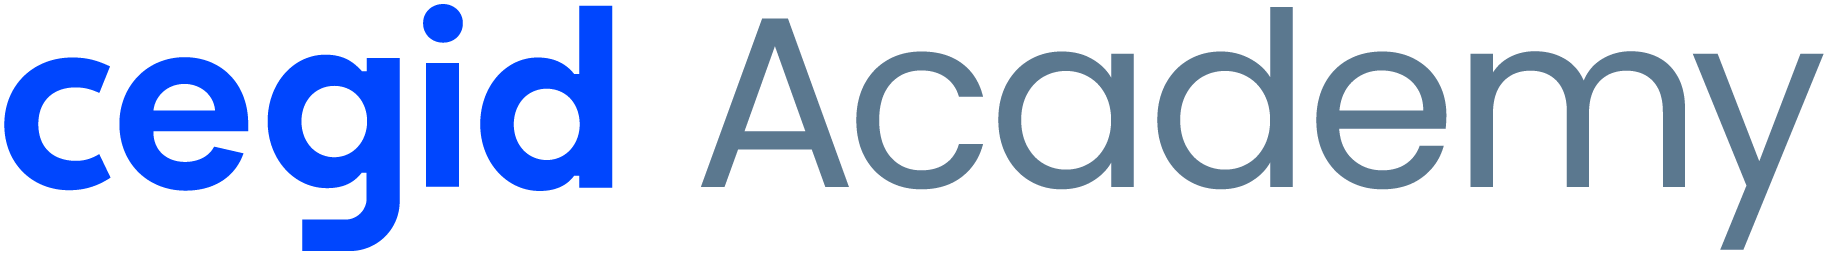<div style="font-size:22px; font-weight:700; color:#1A59FD; line-height:1.2;">Fase 3 &middot; Preparação dos Dados</div><div style="font-size:14px; color:#0A2540; margin-top:4px;">Implementação de Modelos Analíticos com Python &nbsp;&middot;&nbsp; Projeto CRISP-DM · <i>Data Preparation</i> &nbsp;&middot;&nbsp; Versão <b>formandos</b> &nbsp;&middot;&nbsp; Apoio: <b>M3.01 · M3.02</b></div><div style="margin-top:10px;"><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">1. Entendimento do Negócio</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">2. Entendimento dos Dados</span><span style="display:inline-block;background:#1A59FD;color:#FFFFFF;font-weight:600;border:1px solid #1A59FD;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">3. Preparação dos Dados</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">4. Modelação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">5. Avaliação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">6. Deployment</span></div></div>

#### Identificação do projeto

| Campo | Preenchimento |
|---|---|
| **Projeto** | |
| **Grupo** | |
| **Formandos** | |
| **Data** | |
| **Dataset** | |

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Objetivo</div>Transformar dados brutos em dados <b>modeláveis</b>: garantir qualidade, reduzir ruído e evitar enviesamentos. É tipicamente a fase que consome <b>60–80% do tempo</b> do projeto. Todas as decisões devem vir da síntese da Fase 2.</div>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Data leakage</div><b>Regra de ouro contra o <i>data leakage</i>:</b> qualquer transformação que <b>aprende parâmetros</b> dos dados (média/mediana da imputação, categorias do encoding, média e desvio do scaling, componentes do PCA, limites de outliers, target encoding) deve ser ajustada <b>apenas no conjunto de treino</b> e depois aplicada ao teste. Por isso, a divisão treino/teste é feita <b>antes</b> dessas transformações.</div>

**Ordem recomendada (M3)**

1. Seleção de dados → 2. Limpeza determinística → 3. **Separação treino/teste** → 4. Feature engineering → 5. Valores em falta → 6. Outliers → 7. Encoding → 8. Scaling → 9. Redução de dimensionalidade → 10. Pipeline final → 11. Exportação

### 0. Configuração
<hr>

Usar **a mesma configuração** do notebook 02.

**0.1 Bibliotecas**
- `numpy`, `pandas`, `matplotlib`, `seaborn`, `json`, `pathlib`.
- Do scikit-learn: `train_test_split`, encoders (`OneHotEncoder`, `LabelEncoder`, `OrdinalEncoder`), scalers, imputers (`SimpleImputer`, `KNNImputer`), seleção (`VarianceThreshold`, `SelectKBest`, `RFE`), `PCA`, `Pipeline` e `ColumnTransformer`.

In [ ]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, LabelEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.preprocessing import FunctionTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, RFE
from sklearn.feature_selection import chi2, f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression  # estimador usado pelo RFE
from sklearn.decomposition import PCA

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


Bibliotecas carregadas.


**0.2 Configuração do projeto** — os **mesmos** valores do notebook 02 (`PROJETO`, `DATA_PATH`, `TARGET`, `PROBLEM_TYPE`, `ID_COLS`, `RANDOM_STATE`, `TEST_SIZE`).

In [4]:
PROJETO = "HR-Job-Change"
DATA_PATH = "Data/input/Dados_RH_Mudanca_Emprego.csv"
TARGET = "procura_mudanca_emprego"
PROBLEM_TYPE = "classificacao" 
ID_COLS = ["id_candidato"]
RANDOM_STATE = 42
TEST_SIZE = 0.2

df = pd.read_csv(DATA_PATH)
print(df.shape)  

(19158, 14)


**0.3 Estrutura de pastas** — igual ao notebook 02 (`Data/input`, `Data/output`, `Data/analytics`, `Data/models`).

In [5]:
PASTAS = ["Data/input", "Data/output", "Data/analytics", "Data/models"]
for pasta in PASTAS:
    Path(pasta).mkdir(parents=True, exist_ok=True)

def guardar_figura(nome):
    caminho = Path("Data/analytics") / f"{nome}.png"
    plt.savefig(caminho, dpi=150, bbox_inches="tight")
    print(f"Figura guardada em: {caminho}")

**0.4 Carregar os dados**
- Ler o dataset original para `df_raw` e trabalhar numa cópia `df` (o original nunca é alterado).

In [6]:
df_raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

# Cópia de trabalho: todas as alterações são feitas aqui
df = df_raw.copy()

# Verificações rápidas
print("Dimensão:", df.shape)            # esperado: (19158, 14)
print("\nColunas:", df.columns.tolist())
print("\nDistribuição do target:")
print(df[TARGET].value_counts(normalize=True).round(3))

df.head()

Dimensão: (19158, 14)

Colunas: ['id_candidato', 'cidade', 'indice_desenvolvimento_cidade', 'genero', 'experiencia_relevante', 'inscricao_universidade', 'nivel_educacao', 'area_formacao', 'anos_experiencia', 'dimensao_empresa', 'tipo_empresa', 'anos_desde_ultimo_emprego', 'horas_formacao', 'procura_mudanca_emprego']

Distribuição do target:
procura_mudanca_emprego
Não    0.751
Sim    0.249
Name: proportion, dtype: float64


,id_candidato,cidade,indice_desenvolvimento_cidade,genero,experiencia_relevante,inscricao_universidade,nivel_educacao,area_formacao,anos_experiencia,dimensao_empresa,tipo_empresa,anos_desde_ultimo_emprego,horas_formacao,procura_mudanca_emprego
0,760695,Zona_049,0.910,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",6 anos,500 a 999,Empresa privada,1 ano,21,Não
1,789493,Zona_006,0.920,Feminino,Com experiência relevante,Não inscrito,Mestrado,Humanidades,Mais de 20 anos,100 a 500,Startup financiada,2 anos,74,Não
2,211612,Zona_007,0.924,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",9 anos,10 a 49,Empresa privada,1 ano,94,Não
3,521686,Zona_065,0.624,Masculino,Com experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",15 anos,10000 ou mais,Empresa privada,1 ano,75,Não
4,146611,Zona_030,0.698,Masculino,Sem experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",12 anos,500 a 999,ONG,1 ano,157,Não


### 1. Seleção de dados
<hr>

**Descrever que dados serão utilizados no modelo:**

- Que variáveis serão consideradas? Quais serão removidas e porquê?
- Colunas irrelevantes (identificadores, texto livre sem valor, colunas constantes)?
- Variáveis redundantes (a mesma informação noutra forma, ex.: `Attrition` e `AttritionFlag`)?
- Variáveis que **revelam o target** ou que não existiriam no momento da previsão (*leakage*)?
- O dataset será filtrado (por país, período, categoria)?

***Objetivo:*** definir claramente o subconjunto de dados a utilizar.

**1.1 Seleção de dados**
- Remover as colunas irrelevantes, redundantes ou que revelam o alvo (decididas na Fase 2) — `drop(columns=...)`.
- Aplicar filtros de linhas, se fizer sentido.
- Os identificadores (`ID_COLS`) podem ficar no DataFrame para rastreabilidade, mas não vão entrar no modelo.

In [7]:
# 1. Confirmar a redundância cidade ↔ índice (cada cidade tem um único índice)
indices_por_cidade = df.groupby("cidade")["indice_desenvolvimento_cidade"].nunique()
print("Cidades com mais de um índice:", (indices_por_cidade > 1).sum())  # esperado: 0



Cidades com mais de um índice: 0


In [ ]:
# 2. Colunas a remover (decididas na Fase 2)
COLS_REMOVER = ["cidade"]  # redundante com indice_desenvolvimento_cidade; 123 categorias

df = df.drop(columns=COLS_REMOVER)


In [9]:
# 3. Filtros de linhas: nenhum (ver justificação na resposta)

# 4. Definir as features: tudo exceto ID e target
FEATURES = [c for c in df.columns if c not in ID_COLS + [TARGET]]

print("\nDimensão após seleção:", df.shape)  # esperado: (19158, 13)
print(f"\nFeatures ({len(FEATURES)}):", FEATURES)
print("\nFicam no DataFrame mas fora do modelo:", ID_COLS + [TARGET])


Dimensão após seleção: (19158, 13)

Features (11): ['indice_desenvolvimento_cidade', 'genero', 'experiencia_relevante', 'inscricao_universidade', 'nivel_educacao', 'area_formacao', 'anos_experiencia', 'dimensao_empresa', 'tipo_empresa', 'anos_desde_ultimo_emprego', 'horas_formacao']

Ficam no DataFrame mas fora do modelo: ['id_candidato', 'procura_mudanca_emprego']


##### Análise e Interpretação

> *Que variáveis foram removidas e porquê?*

**Resposta:**

- Removida: `cidade`é redundante com `indice_desenvolvimento_cidade`: cada cidade tem sempre o mesmo índice (verificado: 0 cidades com mais de um valor). Além disso tem 123 categorias, 106 delas com menos de 1% das linhas (secção 4), o que daria origem a muitas colunas no one-hot encoding e a categorias com poucos exemplos (24,8% das células com frequência esperada < 5 no qui-quadrado, secção 5.5.3). O índice guarda a informação essencial (r = -0,34 com o alvo; d de Cohen ≈ -0,84) numa única coluna numérica
- Mantida mas fora do modelo: `id_candidato` é um identificador único, sem valor preditivo. Fica no DataFrame para rastreabilidade (permite voltar a identificar cada candidato), mas é excluída da lista de features
- não foram removidas variáveis por data leakage, porque nenhuma revela o target nem seria desconhecida no momento da previsão (Fase 2, secção 7).
- Variáveis fracas mantidas: `horas_formacao`, `genero` e `area_formacao` têm efeito pequeno, mas são mantidas numa primeira versão
- Sem filtros de linhas: não existe país, período ou categoria que justifique excluir candidatos, e remover linhas com nulos eliminaria 53,3% dos dados e informação útil (a falta de dados está associada ao alvo).

- Resultado: 19 158 linhas, 11 features + `id_candidato` + target.

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Exemplo HR (regressão de <code>MonthlyIncome</code>): foram removidos <code>EmployeeID</code> (identificador), <code>Attrition</code> (redundante) e <code>AttritionFlag</code> (rótulo de saída que enviesaria a estimação salarial).</div>

### 2. Limpeza determinística (antes da divisão)
<hr>

Correções que **não aprendem nada com os dados** e podem ser feitas no dataset completo:

- **Duplicados**: remover os que são erros de registo
- **Tipos de dados**: converter texto para número/data, números para categoria
- **String processing**: remover espaços, uniformizar maiúsculas/minúsculas, corrigir categorias
- **Date/Time processing**: extrair ano, mês, dia da semana, fim de semana, diferenças entre datas
- **Códigos de missing disfarçados** (999, −1, `0` impossível) → `NaN` verdadeiro
- **Colunas redundantes**: a mesma informação noutra forma — e atenção a variáveis que são o **alvo disfarçado** (no Titanic, `alive`) → removê-las é prevenção de *leakage*
- **Inconsistências**: valores impossíveis (negativos, % > 100) → `NaN`
- **Target**: garantir que está codificado (ex.: `"Yes"/"No"` → `1/0`)

> **Determinística** = regra fixa definida por vocês (ex.: `999 → NaN`, `"hr " → "HR"`). Se a regra usa uma estatística dos dados (mediana, quantis, frequências, data mínima do dataset), deixa de ser determinística e passa para depois da divisão.

***Objetivo:*** garantir qualidade e coerência dos dados.

**2.1 Duplicados**
- Remover duplicados (`drop_duplicates`) e indicar quantos foram removidos.

In [10]:
# já tinhamos visto que não há duplicados 

n_antes = len(df)

# 1. Duplicados exatos (todas as colunas, incluindo o ID)
print("Linhas duplicadas (com ID):", df.duplicated().sum())        

# 2. IDs repetidos
print("IDs repetidos:", df["id_candidato"].duplicated().sum()) 

# 3. Duplicados ignorando o ID (perfis iguais)
cols_sem_id = [c for c in df.columns if c not in ID_COLS]
n_dup_sem_id = df.duplicated(subset=cols_sem_id).sum()
print("Linhas iguais ignorando o ID:", n_dup_sem_id)

# 4. Remover apenas duplicados exatos (erros de registo)
df = df.drop_duplicates()

n_depois = len(df)
print(f"\nLinhas antes: {n_antes} | depois: {n_depois} | removidas: {n_antes - n_depois}")

Linhas duplicadas (com ID): 0
IDs repetidos: 0
Linhas iguais ignorando o ID: 60

Linhas antes: 19158 | depois: 19158 | removidas: 0


In [11]:
df[df.duplicated(subset=cols_sem_id, keep=False)].sort_values(cols_sem_id).head(10)

,id_candidato,indice_desenvolvimento_cidade,genero,experiencia_relevante,inscricao_universidade,nivel_educacao,area_formacao,anos_experiencia,dimensao_empresa,tipo_empresa,anos_desde_ultimo_emprego,horas_formacao,procura_mudanca_emprego
627,379167,0.624,Masculino,Com experiência relevante,Curso a tempo inteiro,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",5 anos,10000 ou mais,Empresa privada,1 ano,12,Sim
993,605422,0.624,Masculino,Com experiência relevante,Curso a tempo inteiro,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",5 anos,10000 ou mais,Empresa privada,1 ano,12,Sim
14440,416814,0.624,Masculino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",6 anos,100 a 500,Empresa privada,Nunca,2,Sim
16119,260244,0.624,Masculino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",6 anos,100 a 500,Empresa privada,Nunca,2,Sim
5253,771726,0.624,Masculino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",7 anos,100 a 500,Empresa privada,2 anos,6,Sim
10947,960406,0.624,Masculino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",7 anos,100 a 500,Empresa privada,2 anos,6,Sim
486,280429,0.624,Masculino,Sem experiência relevante,Curso a tempo inteiro,Ensino Secundário,NaN,2 anos,NaN,NaN,Nunca,28,Sim
3551,986376,0.624,Masculino,Sem experiência relevante,Curso a tempo inteiro,Ensino Secundário,NaN,2 anos,NaN,NaN,Nunca,28,Sim
7694,601366,0.624,Masculino,Sem experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",Menos de 1 ano,NaN,NaN,1 ano,14,Sim
15800,726358,0.624,Masculino,Sem experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",Menos de 1 ano,NaN,NaN,1 ano,14,Sim


##### Análise e Interpretação

> *Os duplicados eram erros? Quantos foram removidos?*

**Resposta:**

- Duplicados exatos: 0 não existem linhas repetidas nem IDs repetidos (confirmado também na Fase 2, secção 3.3). O `drop_duplicates()` foi aplicado por segurança, mas removeu 0 linhas (19 158 antes e depois).
- Perfis iguais ignorando o ID: 60 linhas (49 na Fase 2, com a `cidade` incluída; o número aumenta ligeiramente após a remoção da `cidade`). Não são erros de registo: têm `id_candidato` diferentes, ou seja, são candidatos distintos que por acaso têm as mesmas respostas. Com variáveis maioritariamente categóricas e poucas categorias, é normal que pessoas diferentes tenham o mesmo perfil (ex.: homem, STEM, licenciado, 5 anos de experiência...)
- Decisão: manter estas linhas. Removê-las apagaria candidatos reais e alteraria a distribuição dos dados

<hr>

**2.2 String processing (M3.01)**
- Nas variáveis de texto: remover espaços (`str.strip`), espaços repetidos (`str.replace(r"\s+", " ", regex=True)`), uniformizar maiúsculas/minúsculas e corrigir categorias escritas de formas diferentes (`replace`).
- (Se aplicável) extrair informação com regex (`str.extract`).

In [12]:
# tb já tinhamos visto que não havia alterações

cat_cols = df.select_dtypes(exclude="number").columns.drop(TARGET).tolist()
# (o target também é texto, mas tratamo-lo à parte na secção do target)

resumo = []
for col in cat_cols + [TARGET]:
    n_antes = df[col].nunique()

    # 1. Remover espaços no início/fim e espaços repetidos
    df[col] = (df[col]
               .str.strip()
               .str.replace(r"\s+", " ", regex=True))

    n_depois = df[col].nunique()

    # 2. Teste: se ignorarmos maiúsculas/minúsculas, surgem categorias "iguais"?
    n_lower = df[col].str.lower().nunique()

    resumo.append({
        "coluna": col,
        "categorias_antes": n_antes,
        "depois_strip": n_depois,
        "se_minusculas": n_lower,
        "alterou": n_antes != n_depois or n_depois != n_lower
    })

resumo_df = pd.DataFrame(resumo)
resumo_df

,coluna,categorias_antes,depois_strip,se_minusculas,alterou
0,genero,3,3,3,False
1,experiencia_relevante,2,2,2,False
2,inscricao_universidade,3,3,3,False
3,nivel_educacao,5,5,5,False
4,area_formacao,6,6,6,False
5,anos_experiencia,22,22,22,False
6,dimensao_empresa,8,8,8,False
7,tipo_empresa,6,6,6,False
8,anos_desde_ultimo_emprego,6,6,6,False
9,procura_mudanca_emprego,2,2,2,False


##### Análise e Interpretação

> *Que correções de texto foram necessárias?*

**Resposta:**

- foi aplicada, a todas as variáveis de texto (9 features categóricas + target), a remoção de espaços no início/fim (`str.strip`) e de espaços repetidos (`str.replace(r"\s+", " ")`)
- nenhuma correção foi efetivamente necessária: o número de categorias distintas manteve-se igual em todas as colunas antes e depois da limpeza, e uniformizar para minúsculas também não juntaria nenhuma categoria. Não há categorias escritas de formas diferentes, pelo que não foi preciso usar `replace` para as unificar (confirma a secção 3.5 da Fase 2).
- os valores em falta (`NaN`) não foram alterados pela limpeza;
- Extração com regex: as colunas `anos_experiencia` e `anos_desde_ultimo_emprego` contêm números escritos como texto ("Menos de 1 ano", "Mais de 20 anos", "Nunca"). Em vez de `str.extract`, serão convertidas para numéricas com um mapeamento explícito na secção de tipos de dados, porque alguns valores exigem regras específicas.

<hr>

**2.3 Tipos de dados e datas (M3.01)**
- Converter tipos errados (`pd.to_datetime`, `astype`).
- Se houver datas: criar ano, mês, dia da semana, fim de semana, dias desde uma data de referência **fixa** (ex.: a data de início do contrato — não a data mínima do dataset) (`.dt`).

In [13]:
# não temos datas mas podemos já converter as colunas com "anos" que estão como texto para numeros

for col in ["anos_experiencia", "anos_desde_ultimo_emprego"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False), "\n")

--- anos_experiencia ---
anos_experiencia
Mais de 20 anos    3286
5 anos             1430
4 anos             1403
3 anos             1354
6 anos             1216
2 anos             1127
7 anos             1028
10 anos             985
9 anos              980
8 anos              802
15 anos             686
11 anos             664
14 anos             586
1 ano               549
Menos de 1 ano      522
16 anos             508
12 anos             494
13 anos             399
17 anos             342
19 anos             304
18 anos             280
20 anos             148
NaN                  65
Name: count, dtype: int64 

--- anos_desde_ultimo_emprego ---
anos_desde_ultimo_emprego
1 ano             8040
Mais de 4 anos    3290
2 anos            2900
Nunca             2452
4 anos            1029
3 anos            1024
NaN                423
Name: count, dtype: int64 



In [14]:
def converter_anos(serie, especiais):
    """Converte texto de anos para número.
    1) aplica o dicionário de casos especiais;
    2) nos restantes, extrai o primeiro número do texto."""
    numeros = serie.str.extract(r"(\d+)")[0]          # ex.: "5" ou "5 anos" -> "5"
    resultado = serie.map(especiais)                   # casos especiais -> número
    resultado = resultado.fillna(pd.to_numeric(numeros, errors="coerce"))
    return resultado.astype("float")                   # float porque há NaN

# Ajusta as chaves ao texto EXATO que viste no passo 1
ESPECIAIS_EXPERIENCIA = {
    "Menos de 1 ano": 0,
    "Mais de 20 anos": 21,
}
ESPECIAIS_ULTIMO_EMPREGO = {
    "Nunca": 0,
    "Mais de 4 anos": 5,
}

for col, especiais in [("anos_experiencia", ESPECIAIS_EXPERIENCIA),
                       ("anos_desde_ultimo_emprego", ESPECIAIS_ULTIMO_EMPREGO)]:
    nulos_antes = df[col].isna().sum()
    df[col] = converter_anos(df[col], especiais)
    nulos_depois = df[col].isna().sum()
    print(f"{col}: tipo = {df[col].dtype} | nulos antes = {nulos_antes} | depois = {nulos_depois}")

anos_experiencia: tipo = float64 | nulos antes = 65 | depois = 65
anos_desde_ultimo_emprego: tipo = float64 | nulos antes = 423 | depois = 423


In [15]:
# Mostra os textos originais que ficaram NaN sem o serem antes
col = "anos_experiencia"
falhas = df_raw.loc[df[col].isna() & df_raw[col].notna(), col].unique()
print(falhas)

<StringArray>
[]
Length: 0, dtype: str


In [16]:
print(df[["anos_experiencia", "anos_desde_ultimo_emprego"]].describe())

print("\nTaxa de 'Sim' por anos de experiência (deve descer, como na Fase 2):")
print(df.groupby("anos_experiencia")[TARGET]
        .apply(lambda s: (s == "Sim").mean())
        .round(3))

       anos_experiencia  anos_desde_ultimo_emprego
count      19093.000000               18735.000000
mean          10.100141                   2.000427
std            6.777024                   1.675596
min            0.000000                   0.000000
25%            4.000000                   1.000000
50%            9.000000                   1.000000
75%           16.000000                   3.000000
max           21.000000                   5.000000

Taxa de 'Sim' por anos de experiência (deve descer, como na Fase 2):
anos_experiencia
0.0     0.454
1.0     0.424
2.0     0.332
3.0     0.353
4.0     0.326
5.0     0.288
6.0     0.282
7.0     0.295
8.0     0.243
9.0     0.217
10.0    0.210
11.0    0.227
12.0    0.186
13.0    0.193
14.0    0.183
15.0    0.166
16.0    0.142
17.0    0.167
18.0    0.154
19.0    0.174
20.0    0.223
21.0    0.153
Name: procura_mudanca_emprego, dtype: float64


##### Análise e Interpretação

> *Que conversões foram feitas? As novas variáveis temporais fazem sentido para o problema?*

**Resposta:**

- Conversões feitas: `anos_experiencia` e `anos_desde_ultimo_emprego` estavam guardadas como texto, embora representem quantidades. Foram convertidas para numéricas (`float`, porque mantêm valores em falta):
  - `anos_experiencia`: "Menos de 1 ano" → 0; "Mais de 20 anos" → 21; restantes valores → o número indicado (1 a 20)
  - `anos_desde_ultimo_emprego`: "Nunca" → 0; "Mais de 4 anos" → 5; restantes → o número indicado (1 a 4)
- Justificação dos valores especiais: os limites abertos ("Mais de 20", "Mais de 4") foram codificados como o valor seguinte (21 e 5), para manter a ordem sem inventar um valor exato. "Menos de 1 ano" e "Nunca" foram codificados como 0 (nenhum ano de experiência / nunca mudou de emprego)
- Verificação: o número de nulos manteve-se igual antes e depois da conversão (nenhum texto ficou por converter); os nulos originais (0,34% e 2,21%) serão tratados depois da divisão treino/teste. A relação com o alvo manteve-se: a taxa de "Sim" desce à medida que os anos de experiência aumentam
- Porque converter: como números, os modelos passam a usar a ordem (5 anos < 10 anos) e evitam-se 22 colunas de one-hot para `anos_experiencia`.
- Datas: o dataset não tem variáveis de data nem informação temporal, pelo que não foram criadas variáveis temporais (ano, mês, dia da semana, etc.). `anos_desde_ultimo_emprego` já é, ela própria, uma medida de tempo.
- `dimensao_empresa` e `nivel_educacao` mantêm-se como texto nesta fase; serão codificadas como ordinais na secção de encoding, depois da divisão.

<hr>

**2.4 Códigos de missing e inconsistências (M3.01)**
- Converter códigos de missing disfarçados (999, −1, 0 impossível) e valores impossíveis em `np.nan`.

In [17]:
# já tinhamos visto antes que não temos valores impossíveis

# 1. Regras de validade (definidas por nós, fixas = determinísticas)
REGRAS_VALIDAS = {
    "indice_desenvolvimento_cidade": (0, 1),    # é um índice entre 0 e 1
    "horas_formacao":                (1, 1000), # horas positivas; >1000 seria implausível
    "anos_experiencia":              (0, 21),   # 0 = "Menos de 1 ano"; 21 = "Mais de 20"
    "anos_desde_ultimo_emprego":     (0, 5),    # 0 = "Nunca"; 5 = "Mais de 4"
}
CODIGOS_MISSING = [999, 9999, -1, -999]

resumo = []
for col, (minimo, maximo) in REGRAS_VALIDAS.items():
    nulos_antes = df[col].isna().sum()

    # Códigos disfarçados -> NaN
    df.loc[df[col].isin(CODIGOS_MISSING), col] = np.nan
    # Fora do intervalo válido -> NaN
    df.loc[(df[col] < minimo) | (df[col] > maximo), col] = np.nan

    resumo.append({
        "coluna": col,
        "min": df[col].min(), "max": df[col].max(),
        "convertidos_em_nulo": df[col].isna().sum() - nulos_antes
    })

pd.DataFrame(resumo)

,coluna,min,max,convertidos_em_nulo
0,indice_desenvolvimento_cidade,0.448,0.949,0
1,horas_formacao,1.000,336.000,0
2,anos_experiencia,0.000,21.000,0
3,anos_desde_ultimo_emprego,0.000,5.000,0


In [18]:
# 2. Missing disfarçado nas categóricas (texto que significa "não sei")
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
TEXTOS_MISSING = ["", "-", "?", "n/a", "na", "nan", "none", "null",
                  "desconhecido", "sem informação", "não sabe"]

for col in cat_cols:
    suspeitos = df[col].dropna().str.lower().isin(TEXTOS_MISSING).sum()
    print(f"{col}: {suspeitos} valores suspeitos")

genero: 0 valores suspeitos
experiencia_relevante: 0 valores suspeitos
inscricao_universidade: 0 valores suspeitos
nivel_educacao: 0 valores suspeitos
area_formacao: 0 valores suspeitos
dimensao_empresa: 0 valores suspeitos
tipo_empresa: 0 valores suspeitos
procura_mudanca_emprego: 0 valores suspeitos


In [19]:
# 3. Coerência entre colunas (só para relatar, não converter)
incoerentes = df[df["anos_desde_ultimo_emprego"] > df["anos_experiencia"] + 1]
print("Casos com mais anos desde o último emprego do que de experiência:", len(incoerentes))
incoerentes[["anos_experiencia", "anos_desde_ultimo_emprego"]].value_counts().head()

Casos com mais anos desde o último emprego do que de experiência: 116


anos_experiencia  anos_desde_ultimo_emprego
0.0               2.0                          44
3.0               5.0                          35
0.0               5.0                          21
                  3.0                           8
                  4.0                           8
Name: count, dtype: int64

##### Análise e Interpretação

> *Que valores foram convertidos em nulos e porquê?*

**Resposta:**

- Nenhum valor foi convertido em nulo. Foram definidas regras de validade fixas para as 4 variáveis numéricas (`indice_desenvolvimento_cidade` entre 0 e 1; `horas_formacao` entre 1 e 1000; `anos_experiencia` entre 0 e 21; `anos_desde_ultimo_emprego` entre 0 e 5) e procurados códigos típicos de missing disfarçado (999, 9999, -1, -999). Todos os valores estão dentro dos limites e não há códigos disfarçados (confirma a secção 3.4 da Fase 2).
- Categóricas: não há textos que signifiquem "valor desconhecido" ("-", "?", "N/A", vazio...). A categoria "Outro" foi mantida porque é uma resposta válida e não um valor em falta.
- Coerência entre colunas: foram encontrados 116 casos em que os anos desde o último emprego são superiores aos anos de experiência. Não foram convertidos em nulos, porque o significado exato das variáveis não é conhecido (podem existir pausas na carreira ou a experiência pode referir-se só à área relevante); ficam registados como observação.
- Os nulos que existem são os originais (ex.: `tipo_empresa` 32,05%), tratados como informativos e preenchidos depois da divisão treino/teste.


<hr>

**2.5 [Classificação] Codificar o alvo**
- Se o target estiver em texto, convertê-lo em números com `LabelEncoder` e mostrar o mapeamento (`classes_`).
- Garantir que a **classe de interesse** (a que se quer detetar: sair, fraude, doença…) fica codificada como `1`: precision, recall e F1 usam `pos_label=1` por omissão. O `LabelEncoder` ordena alfabeticamente — em binário, um `map` explícito (ex.: `{"No": 0, "Yes": 1}`) é mais seguro.

In [20]:
# 1. Confirmar os valores do target antes de codificar
print("Valores do target:", df[TARGET].unique())
print(df[TARGET].value_counts(), "\n")

# 2. Versão "de demonstração": LabelEncoder (ordem alfabética)
le = LabelEncoder()
le.fit(df[TARGET])
print("LabelEncoder - classes_:", le.classes_)  # posição 0 = 'Não', posição 1 = 'Sim'
print("Mapeamento:", dict(zip(le.classes_, le.transform(le.classes_))), "\n")

# 3. Versão usada: map explícito (a classe de interesse fica em 1, de certeza)
MAPA_TARGET = {"Não": 0, "Sim": 1}
df[TARGET] = df[TARGET].map(MAPA_TARGET)

# 4. Verificações
print("Nulos no target após codificação:", df[TARGET].isna().sum())  # tem de dar 0
print("Tipo:", df[TARGET].dtype)
print(df[TARGET].value_counts())
print("\nProporção de 1 (Sim):", round(df[TARGET].mean(), 3))      # esperado: ~0.249

Valores do target: <StringArray>
['Não', 'Sim']
Length: 2, dtype: str
procura_mudanca_emprego
Não    14381
Sim     4777
Name: count, dtype: int64 

LabelEncoder - classes_: ['Não' 'Sim']
Mapeamento: {'Não': np.int64(0), 'Sim': np.int64(1)} 

Nulos no target após codificação: 0
Tipo: int64
procura_mudanca_emprego
0    14381
1     4777
Name: count, dtype: int64

Proporção de 1 (Sim): 0.249


- O target `procura_mudanca_emprego` estava em texto ("Sim"/"Não") e foi convertido para numérico com um mapeamento explícito: Não = 0 e Sim = 1
- A classe de interesse é "Sim" (o candidato procura mudar de emprego), porque é a que a empresa quer detetar. Ficou codificada como 1, que é a classe positiva que as métricas (precision, recall, F1) usam por omissão (`pos_label=1`).
- O `LabelEncoder` daria o mesmo resultado (ordena alfabeticamente: "Não" < "Sim"), mas o `map` explícito foi preferido por ser mais seguro e legível: a codificação não depende da ordem alfabética.
- Verificação: nenhum valor ficou por codificar (0 nulos); as contagens mantêm-se (14 381 zeros e 4 777 uns), e a média do target, 0,249, corresponde à taxa de "Sim".

### 3. Separação dos dados (treino / teste)
<hr>

- Proporção: 80/20 ou 70/30 (compromisso entre dados para aprender e dados para validar)
- `random_state` → reprodutibilidade
- `stratify=y` em classificação → mantém a proporção das classes em treino e teste
- O **conjunto de teste fica "intocado"** até à avaliação do modelo final (Fase 4, secção 7, e Fase 5): não é usado para escolher variáveis, estratégias de preparação, modelos, hiperparâmetros ou limiares
- **Dados temporais** → divisão cronológica (dados ordenados por data e `shuffle=False`, ou corte por data) em vez de aleatória
- **Várias linhas por entidade** → divisão por grupo (`GroupShuffleSplit`), para a mesma entidade não ficar no treino e no teste
- A validação cruzada é feita na Fase 4, **apenas com o treino**

***Objetivo:*** garantir uma avaliação justa e evitar *data leakage*.

**3.1 [Classificação / Regressão] Separar X e y e dividir treino/teste**
- `X` = todas as colunas exceto o target; `y` = target.
- `train_test_split` com `test_size=TEST_SIZE`, `random_state=RANDOM_STATE` e `stratify=y` em classificação.
- Mostrar as dimensões de `X_train` e `X_test`.

In [23]:
# 1. Separar X e y
X = df.drop(columns=[TARGET])
y = df[TARGET]

print("X:", X.shape, "| y:", y.shape)   # esperado: (19158, 11) | (19158,)



X: (19158, 11) | y: (19158,)


In [ ]:
# 2. Dividir treino/teste (80/20, estratificado)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,          # 0.2
    random_state=RANDOM_STATE,    # 42
    stratify=y                    # mesma proporção de 0/1 nos dois conjuntos
)

print("\nX_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test: ", X_test.shape,  "| y_test: ", y_test.shape)




X_train: (15326, 11) | y_train: (15326,)
X_test:  (3832, 11) | y_test:  (3832,)


In [29]:
# 3. Confirmar a estratificação
proporcoes = pd.DataFrame({
    "Total":  y.value_counts(normalize=True),
    "Treino": y_train.value_counts(normalize=True),
    "Teste":  y_test.value_counts(normalize=True),
}).round(3)
proporcoes.index = ["0 (Não)", "1 (Sim)"]
proporcoes

,Total,Treino,Teste
0 (Não),0.751,0.751,0.751
1 (Sim),0.249,0.249,0.249


**3.2 [Classificação] Verificar a estratificação**
- Comparar a proporção das classes no dataset, no treino e no teste.

In [ ]:
# 1. Tabela com contagens e proporções em cada conjunto
conjuntos = {"Total": y, "Treino": y_train, "Teste": y_test}

tabela = pd.DataFrame({
    nome: {
        "n_linhas": len(serie),
        "n_Não (0)": (serie == 0).sum(),
        "n_Sim (1)": (serie == 1).sum(),
        "% Sim (1)": round(serie.mean() * 100, 2),
    }
    for nome, serie in conjuntos.items()
}).T

print(tabela)

        n_linhas  n_Não (0)  n_Sim (1)  % Sim (1)
Total    19158.0    14381.0     4777.0      24.93
Treino   15326.0    11504.0     3822.0      24.94
Teste     3832.0     2877.0      955.0      24.92



Diferença máxima de % Sim entre conjuntos: 0.02 p.p.
Figura guardada em: Data\analytics\03_estratificacao_treino_teste.png


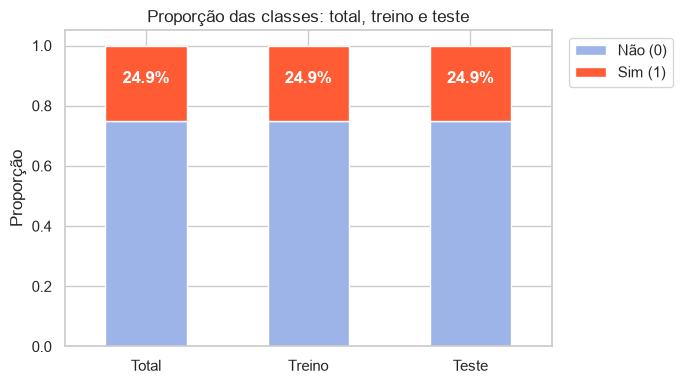

In [32]:
# 2. Diferença máxima de % Sim entre conjuntos (em pontos percentuais)
dif = tabela["% Sim (1)"].max() - tabela["% Sim (1)"].min()
print(f"\nDiferença máxima de % Sim entre conjuntos: {dif:.2f} p.p.")

# 3. Gráfico: proporção de cada classe por conjunto
props = pd.DataFrame({
    nome: serie.value_counts(normalize=True).sort_index()
    for nome, serie in conjuntos.items()
}).T
props.columns = ["Não (0)", "Sim (1)"]

ax = props.plot(kind="bar", stacked=True, figsize=(7, 4), color=["#9DB4E8", "#FF5B34"])
ax.set_ylabel("Proporção")
ax.set_title("Proporção das classes: total, treino e teste")
ax.set_xticklabels(props.index, rotation=0)
for i, v in enumerate(props["Sim (1)"]):
    ax.text(i, 1 - v / 2, f"{v:.1%}", ha="center", color="white", fontweight="bold")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
guardar_figura("03_estratificacao_treino_teste")
plt.show()

##### Análise e Interpretação

> *A estratificação manteve as proporções? Porque é que isto é importante?*

**Resposta:**
A estratificação manteve as proporções?
- Sim. A proporção de "Sim" (1) é praticamente igual nos três conjuntos: 24,9%** no dataset completo, 24,9% no treino e 24,9% no teste (diferença máxima de 0,02 pontos percentuais). O mesmo acontece com "Não" (0), ~75,1% em todos.

Porque é que isto é importante?
- O teste representa a realidade. As classes estão desequilibradas (~3:1). Numa divisão aleatória sem estratificação, o teste podia ficar, por acaso, com mais ou menos "Sim" do que o real, e as métricas deixariam de refletir o desempenho que o modelo terá na prática.
- Métricas fiáveis e comparáveis. Precision, recall, F1 e ROC-AUC da classe "Sim" dependem de quantos "Sim" existem no teste. Com proporções iguais, a avaliação é justa e a baseline de referência (accuracy de 75,1% a prever sempre "Não") é a mesma no treino e no teste.
- O modelo aprende com a mesma distribuição que vai encontrar. O treino tem a mesma proporção de "Sim" que o teste e que os dados reais, por isso o que o modelo aprende é coerente com o que vai ser avaliado.
- Suficientes casos da classe minoritária. A estratificação garante que o teste tem cerca de 955 casos "Sim", um número suficiente para avaliar se o modelo os consegue detetar.

- Nota: a estratificação não corrige o desequilíbrio, apenas o mantém igual em treino e teste. A forma de o compensar (ex.: `class_weight="balanced"`, escolha do limiar, métricas adequadas) será decidida na modelação, usando só o treino.

<hr>

**3.1 [Clustering] Dados para clustering**
- Não há target nem divisão treino/teste: usar o dataset completo como `X_train` (e `X_test = None`).

In [ ]:
# não se aplica

### 4. Engenharia de variáveis (Feature Engineering)
<hr>

Criar novas variáveis a partir das existentes para **extrair mais informação** dos dados que já temos:

| Tipo | Exemplo | Para que serve |
|---|---|---|
| Razão | `petal_ratio = petal_length / petal_width` · `fare_per_person = fare / family_size` | captar proporções |
| Soma / diferença | `family_size = sibsp + parch + 1` | agregar informação relacionada |
| Indicador binário | `is_alone = 1 se family_size == 1` | simplificar uma condição relevante |
| Transformação | `log_fare = log(fare + 1)` | reduzir assimetria |
| Discretização | `age_group = child / adult / senior` (`pd.cut`) | categorias interpretáveis |
| Interação | `area = length * width` | efeitos combinados |
| Temporal | ano, mês, dia da semana, antiguidade | padrões temporais |

> **Atenção:** `pd.cut` com limites fixos escolhidos por vocês é determinístico; `pd.qcut` (quantis), agregados por grupo (ex.: média salarial por departamento) e contagens/frequências **aprendem com os dados** → calcular no treino e aplicar ao teste. Nunca usar o target para criar variáveis (exceto o target encoding controlado da secção 7).

- Qual a motivação de cada variável? Existe fundamentação teórica ou empírica (Fase 2)?

***Objetivo:*** melhorar a capacidade explicativa do modelo.

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Regras <b>determinísticas</b> (que não aprendem com os dados) podem ser aplicadas da mesma forma a treino e teste através de uma função. A análise do impacto das novas variáveis faz-se <b>no treino</b>.</div>

**4.1 Feature engineering (M3.01)**
- Criar uma função `criar_features(data)` com as variáveis derivadas escolhidas (razões, somas/diferenças, indicadores binários, `log1p`, binning com `pd.cut`, interações, componentes de datas).
- Aplicá-la **da mesma forma** a `X_train` e `X_test` e listar as novas variáveis.

##### Análise e Interpretação

> *Que variáveis foram criadas e com que motivação (teórica ou vinda da Fase 2)?*

**Resposta:**

- 

<hr>

**4.2 [Classificação] Avaliar as novas variáveis (no treino)**
- Para cada nova variável: `barplot` da taxa do target (se tiver poucos valores) ou boxplot por classe.

##### Análise e Interpretação

> *As novas variáveis separam melhor as classes do que as originais?*

**Resposta:**

- 

<hr>

**4.2 [Regressão] Avaliar as novas variáveis (no treino)**
- Correlação das novas variáveis numéricas com o target.

##### Análise e Interpretação

> *As novas variáveis têm relação mais forte com o alvo do que as originais?*

**Resposta:**

- 

<hr>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div>Criar muitas colunas sem critério aumenta o ruído e o risco de <b>overfitting</b>. Nem todas as variáveis criadas melhoram o problema — mantenham apenas as que têm justificação.</div>

#### Definição das listas de variáveis

A partir daqui trabalha-se com listas explícitas de variáveis numéricas e categóricas (sem IDs nem target).

**4.3 Listas finais de variáveis**
- Criar `NUM_COLS` e `CAT_COLS` a partir de `X_train`, sem identificadores nem target.
- Ajustar manualmente, se necessário (ex.: numérica que é na verdade categórica).

### 5. Valores em falta
<hr>

**Estratégias possíveis**

| Estratégia (M3.02) | Quando | Nota |
|---|---|---|
| Remover **linhas** (`dropna`) | poucos nulos, MCAR | perde dados |
| Remover **colunas** | coluna quase toda nula (ex.: `deck`) | perde a variável |
| Imputar **média** | numérica simétrica | sensível a outliers |
| Imputar **mediana** | numérica assimétrica | robusta |
| Imputar **moda** | categórica | — |
| Imputar **constante** | "Desconhecido" / 0 | preserva o "não sabido" |
| Imputar **por grupo** | há grupos informativos (ex.: mediana da idade por classe) | melhor estimativa |
| **KNNImputer** | relações entre variáveis | mais custoso |
| **IterativeImputer (MICE)** | missing complexo | modela cada coluna |
| **Indicador de missing** (`add_indicator=True`) | o facto de faltar é informativo | cria uma flag |

Os valores usados na imputação são calculados **no treino** (o imputer dentro do Pipeline garante isto).

**5.1 Valores em falta no treino**
- Tabela com nº e % de nulos por coluna em `X_train` (só as colunas com nulos).

##### Análise e Interpretação

> *Que variáveis precisam de tratamento? Com que peso?*

**Resposta:**

- 

<hr>

**5.2 Comparar estratégias de imputação (M3.02)**
- Na variável numérica com mais nulos: comparar a distribuição original com a imputação pela média, pela mediana e com `KNNImputer` (tabela `describe` + `kdeplot`).
- (Opcional) Imputação por grupo com `groupby(...).transform("median")`: calcular as medianas por grupo em `X_train` e aplicá-las ao `X_test` com `map` — não usar `transform` no dataset completo nem no teste.

##### Análise e Interpretação

> *Que estratégia deforma menos a distribuição? Qual escolhem e porquê?*

**Resposta:**

- 

<hr>

**5.3 Estratégias escolhidas**
- Guardar em variáveis as decisões que vão para o Pipeline: `ESTRATEGIA_NUM` (`"mean"`, `"median"` ou `"knn"`), `ESTRATEGIA_CAT` (`"most_frequent"` ou `"constant"`) e `ADD_INDICATOR` (True/False).

### 6. Outliers
<hr>

- Foram identificados (IQR 1,5×, Z-score ±3, percentis 1%–99%)? Em que variáveis?
- São **erros** (corrigir/remover) ou **valores raros mas reais** (manter)?
- Que decisão foi tomada e qual o critério?

| Opção | Descrição |
|---|---|
| Manter | valores reais e informativos; usar modelos robustos (árvores) ou `RobustScaler` |
| Remover | apenas erros evidentes e **apenas no treino** |
| Limitar (*capping*) | `clip` aos limites IQR calculados no treino |
| *Winsorizing* | `clip` aos percentis 1% e 99% calculados no treino |
| Transformar | `np.log1p` para reduzir o efeito de valores extremos |

**Decisão (M3.02):** erro de medição → remover/corrigir; informação rara real → manter (capping/log preserva a observação sem a deixar dominar). Em variáveis assimétricas preferir **log** ou **RobustScaler** a remover.

**Nunca remover linhas do conjunto de teste:** o teste tem de representar os dados reais que o modelo vai encontrar.

**6.1 Deteção de outliers no treino**
- Para cada numérica: nº de outliers por IQR, Z-score e percentis (P1–P99), guardando os limites IQR calculados no treino.

##### Análise e Interpretação

> *Que variáveis têm outliers? São erros ou valores reais?*

**Resposta:**

- 

<hr>

**6.2 Tratamento de outliers (se aplicável)**
- Aplicar a decisão tomada: capping (`clip` aos limites IQR), winsorizing (`clip` a P1–P99) ou `np.log1p`.
- Os limites são calculados **no treino** e aplicados **da mesma forma** ao teste.

##### Análise e Interpretação

> *Que tratamento foi aplicado e com que critério? Porque não remover as linhas?*

**Resposta:**

- 

<hr>

### 7. Encoding de variáveis categóricas
<hr>

| Estratégia (M3.01) | Quando usar | Cuidado |
|---|---|---|
| **Label / Ordinal** | binárias ou ordinais (com ordem real); `LabelEncoder` no **alvo** | introduz ordem artificial em nominais |
| **One-Hot** | nominais com poucas categorias | aumenta a dimensionalidade; `handle_unknown="ignore"` evita erros com categorias novas |
| **Frequency** | nominais com muitas categorias | categorias com igual frequência colidem |
| **Target / Mean** | muitas categorias, com relação ao alvo | **data leakage** → ajustar **só no treino** |
| **Binary / Hashing** (avançado) | cardinalidade muito alta | menos interpretável |

`pd.get_dummies(drop_first=True)` serve para análises rápidas, mas não guarda as categorias do treino → num projeto preferir o `OneHotEncoder` dentro do Pipeline.

**7.1 Categorias por variável (treino)**
- Para cada categórica: nº de categorias e lista das categorias.

##### Análise e Interpretação

> *Que encoding é adequado a cada variável (nominal, ordinal, binária, alta cardinalidade)?*

**Resposta:**

- 

<hr>

**7.2 One-Hot Encoding**
- `OneHotEncoder(handle_unknown="ignore")` ajustado no treino; mostrar as colunas geradas (`get_feature_names_out`).

##### Análise e Interpretação

> *Quantas colunas foram criadas? Porque é útil o `handle_unknown="ignore"`?*

**Resposta:**

- 

<hr>

**7.3 Outras estratégias de encoding (M3.01)**
- Binária: `(X["col"] == "valor").astype(int)`.
- Frequency encoding: `map(value_counts(normalize=True))` calculado no treino.
- Target encoding: `y_train.groupby(X_train[col]).mean()` — **só no treino**, depois aplicado ao teste.

##### Análise e Interpretação

> *Que estratégia é mais adequada ao vosso caso? Que risco tem o target encoding?*

**Resposta:**

- 

<hr>

**7.4 (Se aplicável) Variáveis ordinais**
- `OrdinalEncoder` com a ordem das categorias explícita.

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div><b>Target Encoding</b> (substituir a categoria pela média do target) usa o próprio target: se for calculado no dataset completo, a informação do teste passa para o treino (<i>leakage</i>). Se o usarem, calculem-no <b>só no treino</b> e apliquem o mapeamento ao teste. Encodings feitos fora do Pipeline (Frequency, Target, Ordinal) têm de ser aplicados da mesma forma a treino e teste <b>antes</b> da secção 10 — e a variável resultante passa para <code>NUM_COLS</code>. Mesmo calculado só no treino, o target encoding manual usa o alvo da <b>própria linha</b>, o que produz overfitting e uma validação cruzada otimista na Fase 4. Alternativa recomendada: <code>TargetEncoder</code> do scikit-learn (versão ≥ 1.3) dentro do Pipeline, que faz <i>cross-fitting</i> internamente.</div>

### 8. Scaling (normalização / escalonamento)
<hr>

| Método (M3.02) | O que faz | Sensível a outliers? | Quando usar |
|---|---|---|---|
| `StandardScaler` | média 0, desvio padrão 1 | sim | uso geral; dados aproximadamente normais |
| `MinMaxScaler` | intervalo [0, 1] | **muito** | quando é preciso um intervalo fixo |
| `RobustScaler` | usa mediana e IQR | não | dados com outliers / assimétricos (usado no pipeline das aulas) |
| `MaxAbsScaler` | divide pelo máximo absoluto | sim | dados esparsos |
| `Normalizer` | normaliza **por linha** (não por coluna) | — | casos específicos (ex.: texto) |
| `PowerTransformer` (Yeo-Johnson) / `QuantileTransformer` | aproximam da normal | reduzem o efeito | corrigir assimetria |

**Precisam de scaling:** KNN, Regressão Logística, SVM, redes neuronais, K-Means, PCA (baseados em distância ou gradiente).
**Não precisam:** árvores de decisão e Random Forest.

**8.1 Comparar scalers (M3.02)**
- Numa variável (a mais assimétrica/com outliers), comparar Standard, MinMax, Robust, MaxAbs, PowerTransformer e QuantileTransformer: tabela `describe` e histogramas.

##### Análise e Interpretação

> *Que scaler é mais adequado aos vossos dados e aos modelos que vão usar?*

**Resposta:**

- 

<hr>

**8.2 Scaler escolhido**
- Guardar a escolha em `SCALER` (nas aulas: `RobustScaler()`).

### 9. Redução de dimensionalidade
<hr>

Reduzir o número de variáveis mantendo o máximo de informação (evita overfitting, reduz ruído, melhora velocidade — "maldição da dimensionalidade").

1. **Feature selection** — manter as variáveis mais relevantes (M3.02): correlação > 0,8, baixa variância (`VarianceThreshold`), testes estatísticos (`SelectKBest`), importância de um Random Forest, `RFE`
2. **Feature extraction** — criar novas componentes: **PCA** (sempre depois de escalonar)

***Objetivo:*** reduzir complexidade e multicolinearidade. Em datasets com poucas variáveis, esta etapa pode concluir que **não é necessário reduzir** — também é uma decisão válida.

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Seleção de variáveis e leakage</div>Os métodos que usam o target (<code>SelectKBest</code>, importância do Random Forest, <code>RFE</code>, correlação com o alvo) aplicam-se <b>só no treino</b> — nunca no dataset completo. Mesmo assim, se a seleção for feita aqui sobre todo o treino e depois se fizer validação cruzada na Fase 4 com as variáveis escolhidas, a CV fica <b>ligeiramente otimista</b>, porque os folds de validação já participaram na escolha. A forma mais rigorosa é colocar a seleção dentro do Pipeline (ex.: passo <code>SelectKBest</code>, com <code>k</code> afinado no GridSearch). Se a fizerem aqui, mencionem esta limitação na Fase 5.</div>

**9.1 Variância baixa**
- `VarianceThreshold` nas numéricas do treino; listar as variáveis quase constantes.

##### Análise e Interpretação

> *Há variáveis que quase não variam?*

**Resposta:**

- 

<hr>

**9.2 Correlação entre preditores**
- Listar os pares com |r| > 0,8 no treino.

##### Análise e Interpretação

> *Que variáveis redundantes podem ser removidas?*

**Resposta:**

- 

<hr>

**9.3 Seleção por teste e por modelo (M3.02)**
- Sobre os dados de treino imputados e codificados: `SelectKBest` (`f_classif` / `f_regression`), importância de um Random Forest (`feature_importances_`) e `RFE` com Logistic/Linear Regression.
- Tabela comparativa.

##### Análise e Interpretação

> *Que variáveis aparecem como importantes em todos os métodos? Onde discordam e porquê?*

**Resposta:**

- 

<hr>

**9.4 PCA**
- Normalizar as numéricas do treino e aplicar `PCA()`; tabela da variância explicada e acumulada; nº de componentes para ≥ 95%; gráfico da variância acumulada.

##### Análise e Interpretação

> *Vale a pena usar PCA? Quantas variáveis se poupariam e o que se perde em interpretabilidade?*

**Resposta:**

- 

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Critério da variância acumulada: 70–80% (redução agressiva, exploração) · 85–90% (bom equilíbrio) · <b>95%</b> (conservador, muito usado) · 99% (perda mínima). Uma redução começa a ser interessante quando se reduzem 40–50% das variáveis mantendo 90–95% da variância. <b>Seleção</b> mantém variáveis interpretáveis; o <b>PCA</b> mantém mais informação mas as componentes perdem significado (M3.02).</div>

**9.5 Decisão**
- Atualizar `NUM_COLS`/`CAT_COLS` com as variáveis a remover e definir `USAR_PCA` (True/False).

### 10. Pipeline final de preparação
<hr>

O `Pipeline` + `ColumnTransformer` junta todas as decisões anteriores num único objeto que:
- evita *data leakage* (é ajustado só no treino — e, na Fase 4, dentro de cada fold da validação cruzada);
- aplica exatamente as mesmas transformações a treino, teste e dados futuros;
- torna o processo reproduzível.

**10.1 Pipeline final de preparação (M3.02)**
- `ColumnTransformer` com:
  - `"num"`: `Pipeline` com imputação (`SimpleImputer(strategy=ESTRATEGIA_NUM, add_indicator=ADD_INDICATOR)`, ou `KNNImputer` se `"knn"`) + `SCALER` (+ PCA se `USAR_PCA`);
  - `"cat"`: `Pipeline` com imputação (`ESTRATEGIA_CAT`) + `OneHotEncoder(handle_unknown="ignore")`.
- `fit_transform` no treino e `transform` no teste; mostrar as dimensões e as primeiras linhas.

##### Análise e Interpretação

> *Quantas colunas tem o dataset preparado? O que foi aprendido no treino e aplicado ao teste?*

**Resposta:**

- 

<hr>

**10.2 Verificação**
- Confirmar que não há valores em falta nos dados preparados.

### 11. Exportação dos dados preparados
<hr>

Gravam-se em `Data/output/`:
- `*_train.csv` / `*_test.csv` — dados **após limpeza e feature engineering, antes das transformações aprendidas** (a Fase 4 volta a ajustá-las dentro do Pipeline);
- `*_train_prepared.csv` / `*_test_prepared.csv` — versão já transformada (consulta / modelos fora do Pipeline);
- `config_projeto.json` — configuração e listas de variáveis, lida pelos notebooks 04, 05 e 06.

Os passos feitos **fora** do Pipeline (limpeza da secção 2, `criar_features`, capping, encodings manuais) não ficam guardados no modelo: na Fase 6 têm de ser reaplicados aos dados novos com os **mesmos parâmetros aprendidos no treino** (limites de capping, mapeamentos de encoding).

**11. Exportação** (necessária para os notebooks 04, 05 e 06)
- Gravar em `Data/output/`:
  - classificação/regressão: `<PROJETO>_train.csv` e `<PROJETO>_test.csv` (X + target, **antes** das transformações aprendidas) e as versões `_prepared`;
  - clustering: `<PROJETO>_dataset_clustering.csv` (e `_prepared`).
- Gravar `Data/output/config_projeto.json` com: `PROJETO`, `TARGET`, `PROBLEM_TYPE`, `ID_COLS`, `NUM_COLS`, `CAT_COLS`, `RANDOM_STATE`, `TEST_SIZE`, `ESTRATEGIA_NUM`, `ESTRATEGIA_CAT`, `ADD_INDICATOR`, `SCALER` (nome da classe) e `USAR_PCA`.
- Gravar os parâmetros aprendidos no treino fora do Pipeline (limites de capping, mapeamentos de frequency/target encoding, medianas por grupo) em `Data/models/<PROJETO>_prep_params.json`, para reutilizar na Fase 6.

### 12. Síntese da Fase de Data Preparation
<hr>

| # | Transformação | Variáveis | Justificação | Aprende com os dados? (ajustada só no treino) |
|---|---|---|---|---|
| 1 | ex.: remoção de identificador | `Intern_ID` | sem valor explicativo | não |
| 2 | ex.: imputação pela mediana | `Age` | distribuição assimétrica | sim |
| 3 | ex.: One-Hot Encoding | `Department`, `Major` | nominais | sim |
| 4 | ex.: StandardScaler | numéricas | LR e KNN sensíveis à escala | sim |

**Descrever também:**
- Impacto esperado no modelo
- Riscos ou limitações introduzidos
- Versão final do dataset preparado (nº de linhas e colunas)

***Objetivo:*** documentar todas as alterações antes da modelação.

**Resposta:**

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Antes de avançar</div>Checklist de autoavaliação da fase<ul style="margin:4px 0 2px 0;"><li>Limpeza dos dados (missing, duplicados, inconsistências) justificada</li><li>Remoção explícita de colunas irrelevantes / identificadores</li><li>Engenharia de variáveis e encoding adequados ao tipo de variável</li><li>Definição explícita de <code>X</code> e <code>y</code></li><li>Divisão treino/teste correta (estratificada em classificação)</li><li>Divisão adequada à estrutura dos dados (aleatória / estratificada / temporal / por grupo)</li><li>Transformações ajustadas no treino — sem <i>data leakage</i></li><li>Nenhuma decisão tomada com base no conjunto de teste</li><li>Dados preparados e configuração exportados</li></ul></div>

[← Fase 2: Entendimento dos Dados](02_data_understanding.ipynb) &nbsp;&nbsp;|&nbsp;&nbsp; [Fase 4: Modelação →](04_modeling.ipynb)

<div style="border-left:7px solid #1A59FD; background:#F3F6FF; color:#0A2540; padding:6px 14px; border-radius:4px; font-size:12px; font-family:Segoe UI, Arial, sans-serif;">Cegid Academy &nbsp;·&nbsp; AiDAPT &nbsp;·&nbsp; Template CRISP-DM v2.0 · versão formandos</div>